# **HIRING PROCESS - RECRUITMENT FUNNEL ANALYSIS**

## 1. **Import Necessary Libraries**

In [70]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 6)

## 2. **Loading the Dataset**

In [71]:
df = pd.read_csv("hiring_data.csv")
df.head()

,candidate_id,department,source,application_date,stage_reached,offer_status,time_to_hire_days
0,1,Sales,Referral,2025-07-03,Screening,Not Applicable,NaN
1,2,Operations,Walk-in,2024-02-13,Screening,Not Applicable,NaN
2,3,HR,Job Portal,2025-11-27,Applied,Not Applicable,NaN
3,4,Marketing,Job Portal,2025-05-18,Applied,Not Applicable,NaN
4,5,Engineering,Walk-in,2024-08-28,Applied,Not Applicable,NaN


## 3. **Basic Data Inspection**

In [72]:
df.shape

(5215, 7)

In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5215 entries, 0 to 5214
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   candidate_id       5215 non-null   int64  
 1   department         5215 non-null   str    
 2   source             5175 non-null   str    
 3   application_date   5215 non-null   str    
 4   stage_reached      5215 non-null   str    
 5   offer_status       5215 non-null   str    
 6   time_to_hire_days  577 non-null    float64
dtypes: float64(1), int64(1), str(5)
memory usage: 529.0 KB


In [74]:
df.isnull().sum()

candidate_id            0
department              0
source                 40
application_date        0
stage_reached           0
offer_status            0
time_to_hire_days    4638
dtype: int64

In [75]:
df.duplicated().sum()

np.int64(15)

## 4. **Data Cleaning**

In [76]:
# Removing the 15 duplicated rows
df = df.drop_duplicates()
df.shape

(5200, 7)

In [77]:
# "source" column has 40 missing values. These values will be replaced with "Unknown" instead of dropping the rows.

df["source"] = df["source"].fillna("Unknown")
df.source.value_counts()

source
LinkedIn        1569
Job Portal      1286
Referral        1080
Campus Drive     727
Walk-in          498
Unknown           40
Name: count, dtype: int64

## 5. **Recruitment Funnel Analysis**

In [78]:
df.stage_reached.value_counts()

stage_reached
Screening    1650
Applied      1619
Interview    1138
Hired         576
Offer         217
Name: count, dtype: int64

In [79]:
stage_order = ["Applied","Screening","Interview","Offer","Hire"]
counts = df["stage_reached"].value_counts()
funnel_df = pd.DataFrame({"stage":stage_order,
                         "candidates":[len(df),
                                       counts["Screening"] + counts["Interview"] + counts["Offer"] + counts["Hired"],
                                       counts["Interview"] + counts["Offer"] + counts["Hired"],
                                       counts["Offer"] + counts["Hired"],
                                       counts["Hired"]
                                      ]})
funnel_df

,stage,candidates
0,Applied,5200
1,Screening,3581
2,Interview,1931
3,Offer,793
4,Hire,576


In [80]:
# Putting the hiring stages in a logical order
stage_order = ["Applied", "Screening", "Interview", "Offer", "Hired"]

# "stage_reached" tells us the final stage that a particular candidate has reached. Which means that they have passed the previous stages.
counts = df["stage_reached"].value_counts()
funnel_df = pd.DataFrame({"stage": stage_order,"candidates": [len(df),
                                         counts["Screening"] + counts["Interview"] + counts["Offer"] + counts["Hired"],
                                         counts["Interview"] + counts["Offer"] + counts["Hired"],
                                         counts["Offer"] + counts["Hired"],
                                         counts["Hired"]]})
print(counts)
print("_"*25)
funnel_df

stage_reached
Screening    1650
Applied      1619
Interview    1138
Hired         576
Offer         217
Name: count, dtype: int64
_________________________


,stage,candidates
0,Applied,5200
1,Screening,3581
2,Interview,1931
3,Offer,793
4,Hired,576


In [81]:
# Drop-off rate between 2 consecutive stages of the hiring process

funnel_df["drop_off_%"] = (1 - funnel_df["candidates"] / funnel_df["candidates"].shift(1)) * 100
funnel_df

,stage,candidates,drop_off_%
0,Applied,5200,NaN
1,Screening,3581,31.134615
2,Interview,1931,46.076515
3,Offer,793,58.933195
4,Hired,576,27.364439


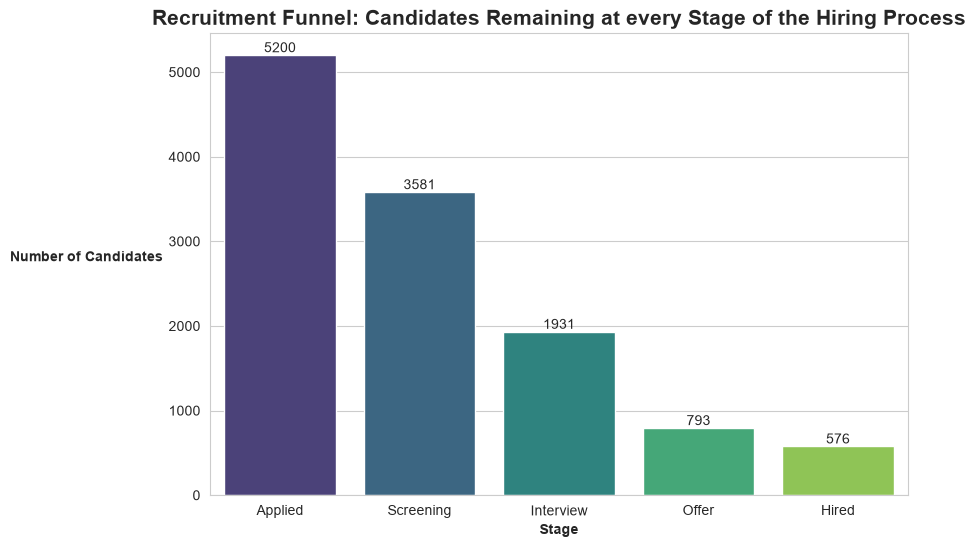

In [82]:
funnel_bar = sns.barplot(data = funnel_df, x="stage", y="candidates", hue="stage", palette="viridis")
plt.title("Recruitment Funnel: Candidates Remaining at every Stage of the Hiring Process", fontweight="bold",fontsize=15)
plt.xlabel("Stage",fontweight="bold")
plt.ylabel("Number of Candidates",fontweight="bold",rotation=0,ha="right")
for container in funnel_bar.containers:
    plt.bar_label(container)
plt.show()

Most number of candidates are eliminated or drop-off between **Applied and Screening** as well as between **Interview and Offer** stages. 

## 6. **Department-wise Hiring Trends**
### Which department has hired the most number of candidates?

In [83]:
department_hires = df[df["stage_reached"] == "Hired"]["department"].value_counts()
pd.DataFrame(department_hires)

,count
department,
Engineering,133
Sales,130
Marketing,104
Finance,86
Operations,69
HR,54


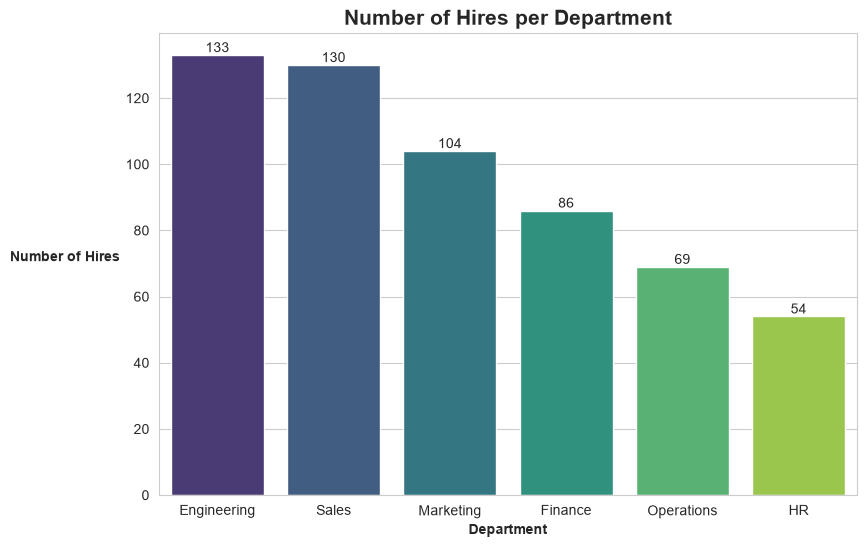

In [84]:
dept_hires = sns.barplot(x=department_hires.index,y=department_hires.values,hue=department_hires.index,palette ="viridis")
plt.xticks(rotation=0)
plt.xlabel("Department",fontweight="bold")
plt.ylabel("Number of Hires",fontweight="bold",rotation=0,ha="right")
plt.title("Number of Hires per Department",fontweight="bold",fontsize=15)
for container in dept_hires.containers:
    plt.bar_label(container)
plt.show()

In [94]:
# Department-wise conversion-rate: Hires/Applicants

total_dept = df["department"].value_counts()
hired_dept = df[df["stage_reached"] == "Hired"]["department"].value_counts()
conversion_rate = (hired_dept / total_dept * 100 ).round(2).sort_values(ascending=False)
pd.DataFrame(conversion_rate)

,count
department,
Operations,13.80
Finance,13.63
Marketing,13.40
Sales,11.66
HR,10.91
Engineering,7.90


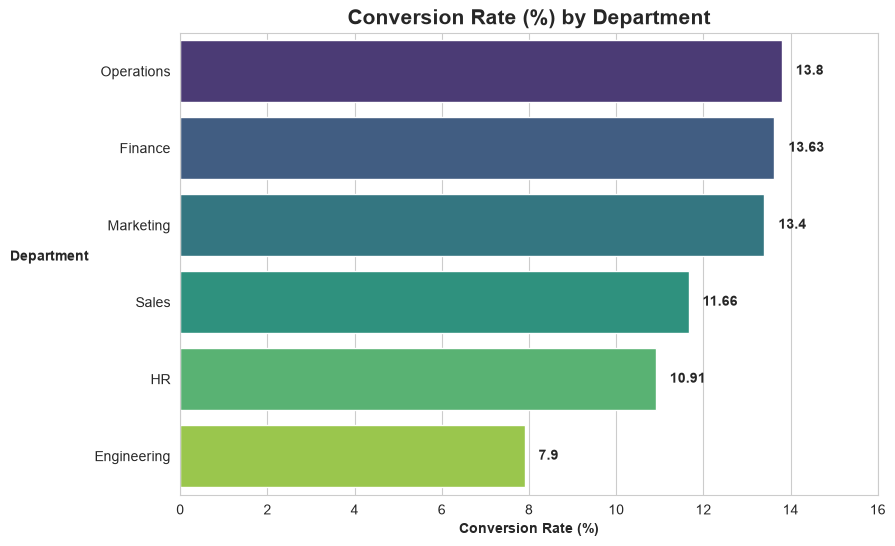

In [95]:
# Plotting conversion-rate by department 

conversion = sns.barplot(x=conversion_rate.values,y=conversion_rate.index,hue=conversion_rate.index, palette="viridis")
plt.xticks(rotation=0)
plt.xlabel("Conversion Rate (%)",fontweight="bold")
plt.ylabel("Department",fontweight="bold",rotation=0,ha="right")
plt.title("Conversion Rate (%) by Department",fontweight="bold",fontsize=15)
plt.xlim(0,16)
for container in conversion.containers:
    plt.bar_label(container, padding=10, fontweight="bold")
plt.show()

## 7. **Time-to-Hire Analysis**
### How long does it take to hire a candidate:
- Overall?
- By Department?

In [87]:
hired_df = df[df["stage_reached"] == "Hired"]

print("Average time to hire a candidate (Overall):", round(hired_df["time_to_hire_days"].mean(), 1), "days")
print("Median time to hire a candidate (Overall):", round(hired_df["time_to_hire_days"].median(), 1), "days")

Average time to hire a candidate (Overall): 32.1 days
Median time to hire a candidate (Overall): 30.2 days


In [88]:
avg_time_dept = hired_df.groupby("department")["time_to_hire_days"].mean().round(1).sort_values()
pd.DataFrame(avg_time_dept)

,time_to_hire_days
department,
Sales,21.9
HR,25.0
Operations,27.6
Marketing,29.2
Finance,35.2
Engineering,47.4


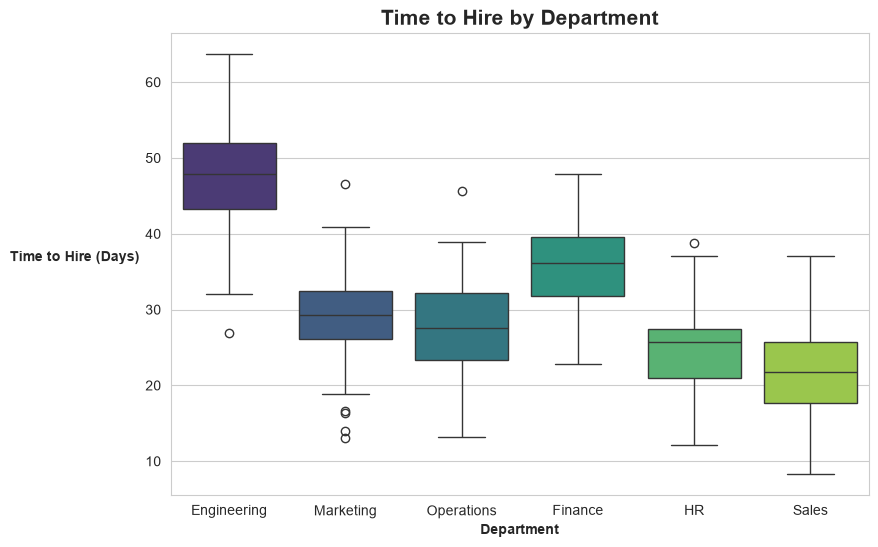

In [89]:
sns.boxplot(data = hired_df, x="department",y="time_to_hire_days",hue="department", palette="viridis")
plt.title("Time to Hire by Department",fontsize=15,fontweight="bold")
plt.xlabel("Department",fontweight="bold")
plt.ylabel("Time to Hire (Days)",fontweight="bold",rotation=0,ha="right")
plt.show()

## 8. **Sourcing Channel Effectiveness**
### Which sourcing channels bring the most candidates and which ones bring in the most qualified candidates turning into hires?

In [96]:
source_appliers = df["source"].value_counts()
source_hires = df[df["stage_reached"] == "Hired"]["source"].value_counts()

source_table = pd.DataFrame({"applied": source_appliers, "hired": source_hires}).fillna(0)
source_table["conversion %"] = (source_table["hired"] / source_table["applied"] * 100).round(2)
source_table.sort_values("conversion %", ascending=False)

,applied,hired,conversion %
source,,,
Referral,1080,146,13.52
Campus Drive,727,88,12.10
Job Portal,1286,138,10.73
Walk-in,498,50,10.04
LinkedIn,1569,151,9.62
Unknown,40,3,7.50


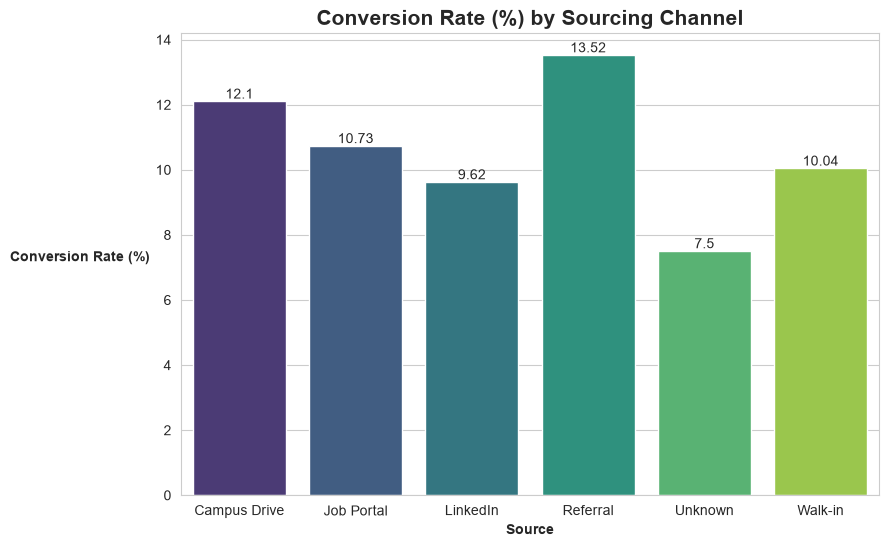

In [97]:
conversion_rate = sns.barplot(x=source_table.index, y=source_table["conversion %"], hue=source_table.index, palette="viridis")
plt.title("Conversion Rate (%) by Sourcing Channel",fontsize = 15, fontweight="bold")
plt.xlabel("Source",fontweight="bold")
plt.ylabel("Conversion Rate (%)",fontweight="bold",rotation=0,ha="right")
for container in conversion_rate.containers:
    plt.bar_label(container)
plt.show()

Campus Drives, Referral candidates appear to convert at a higher rate than other channels, indicating that these are strong sourcing strategies.

## 9. **Sourcing Channel Effectiveness**
### How many candidates accepted the offer and how many declined?

In [98]:
offered = df[df["stage_reached"].isin(["Offer", "Hired"])]
offer_status_counts = offered["offer_status"].value_counts()
offer_status_counts

offer_status
Accepted    576
Declined    217
Name: count, dtype: int64

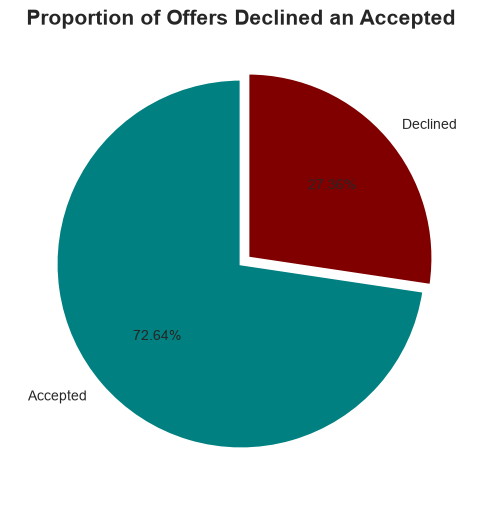

In [100]:
plt.pie(offer_status_counts,labels=offer_status_counts.index,autopct="%1.2f%%",colors=["teal","maroon"],startangle=90, wedgeprops={"edgecolor":"white","linewidth":2},explode=(0,0.05))
plt.title("Proportion of Offers Declined an Accepted", fontweight="bold",fontsize=15)
plt.show()

## 10. **Key Insights & Conclusion**

- The recruitment funnel highlights the stages with the highest candidate drop-offs, helping identify potential bottlenecks in the hiring process.
- Department-wise conversion rates provide insights into which teams have more selective hiring processes and which are more efficient at converting candidates.
- Time-to-hire varies across departments, providing useful benchmarks for setting realistic recruitment timelines and identifying areas for improvement.
- Sourcing channels differ in their ability to convert applicants into hires, helping recruitment teams optimize sourcing strategies and spending.
- The offer acceptance rate provides an indication of how competitive and appealing the organization’s offers are to candidates.
- Overall, these insights can help HR and recruitment teams focus on improving key stages of the hiring funnel, optimizing sourcing channels, and reducing hiring time.

> **Conclusion:** Data-driven recruitment analysis can help organizations identify bottlenecks, improve hiring efficiency, optimize recruitment spending, and make better-informed hiring decisions.